# 01 · Análisis exploratorio de datos (EDA)

**Proyecto:** Alerta temprana de deserción · SENA
**Autor:** Andrés · **Revisor:** David

**Objetivo:** entender los datos procesados antes de construir variables y entrenar el modelo. Buscamos:

1. Cuánta deserción hay y cómo cambia por modalidad y por cohorte.
2. Qué variables se relacionan con la deserción.
3. Qué patrones de valores faltantes hay y qué significan.
4. Qué variables son redundantes entre sí.
5. Diferencias de partida entre grupos, para tenerlas en cuenta al evaluar la equidad.

**Datos:** `data/processed/aprendices.parquet`, salida de la etapa `process` (ver `docs/datos.md`). Este cuaderno solo lee datos: no modifica archivos del pipeline.

## 1. Configuración

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Raíz del repositorio: funciona tanto si el cuaderno se abre desde notebooks/ como desde la raíz.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RUTA_DATOS = RAIZ / "data" / "processed" / "aprendices.parquet"
RUTA_AUDITORIA = RAIZ / "data" / "processed" / "auditoria.parquet"

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4.5)
pd.set_option("display.max_columns", 60)

ETIQUETA = "deserto"

In [2]:
def tasa_por(df: pd.DataFrame, columna: str) -> pd.DataFrame:
    """Tasa de deserción y número de aprendices por cada valor de una columna."""
    return (
        df.groupby(columna, observed=True, dropna=False)[ETIQUETA]
        .agg(tasa_desercion="mean", aprendices="size")
        .sort_values("tasa_desercion", ascending=False)
    )


def graficar_tasa(df: pd.DataFrame, columna: str, titulo: str | None = None) -> None:
    """Barras horizontales con la tasa de deserción por categoría y la tasa global como referencia."""
    tabla = tasa_por(df, columna)
    ax = tabla["tasa_desercion"].plot.barh(color=sns.color_palette()[0])
    ax.axvline(df[ETIQUETA].mean(), color="gray", linestyle="--", label="Tasa global")
    ax.invert_yaxis()
    ax.set_xlabel("Tasa de deserción")
    ax.set_ylabel("")
    ax.set_title(titulo or f"Deserción por {columna}")
    ax.legend()
    plt.show()

## 2. Carga y vista general

In [17]:
df = pd.read_parquet(RUTA_DATOS)
print(f"{df.shape[0]:,} aprendices × {df.shape[1]} columnas")
df.head()

9,518 aprendices × 43 columnas


,id_aprendiz,id_programa,nivel_formacion,area_formacion,modalidad,duracion_programa_meses,jornada,fecha_inicio,dias_desde_inicio,edad,municipio_residencia,nivel_educativo,n_cursos_previos,n_cursos_completados,n_cursos_abandonados,tasa_finalizacion_previa,experiencia_virtual_previa,meses_desde_ultimo_curso,es_primer_curso,abandono_ultimo_curso,tipo_conexion,tipo_plan_internet,calidad_internet,dispositivo_principal,comparte_dispositivo,disponibilidad_equipo,situacion_laboral,horas_trabajo_semana,responsabilidades_cuidado,horas_disponibles_estudio,dificultad_economica_reportada,porcentaje_actividades_entregadas,porcentaje_actividades_aprobadas,promedio_calificaciones,dias_sin_ingreso,ingresos_plataforma_ultimos_7d,actividades_pendientes,evaluaciones_no_presentadas,asistencia_porcentaje,solicito_apoyo,fecha_corte,deserto,id_cohorte
0,A-000008,P-202,OPERARIO,agropecuaria,mixta,6,nocturna,2023-01-23,27,19,Bogotá,basica_secundaria,1,1,0,1.0,False,6.3,False,False,fibra,pospago,media,tableta,False,True,independiente,42,False,7.0,baja,0.843,0.843,5.0,8,9,1,0,1.00,False,2023-02-19,0,2023-T1
1,A-000020,P-402,TECNÓLOGO,administracion,virtual,24,otra,2023-01-23,30,28,Barranquilla,bachillerato,1,1,0,1.0,False,2.1,False,False,fibra,pospago,media,computador,False,True,desempleado,0,False,19.0,alta,0.952,0.952,4.2,0,12,0,0,NaN,False,2023-02-22,0,2023-T1
2,A-000042,P-304,TÉCNICO,salud,mixta,12,diurna,2023-01-23,22,21,Barranquilla,basica_secundaria,0,0,0,NaN,False,NaN,True,<NA>,datos_moviles,prepago,baja,tableta,False,True,empleado,30,False,21.0,baja,0.888,0.739,4.5,1,4,1,0,0.80,False,2023-02-14,1,2023-T1
3,A-000043,P-303,TÉCNICO,administracion,presencial,12,nocturna,2023-01-23,21,30,Barranquilla,bachillerato,2,0,1,0.0,False,16.2,False,True,cable,pospago,alta,celular,False,True,otra,0,False,19.0,alta,0.765,0.701,3.4,4,5,1,0,0.89,False,2023-02-13,1,2023-T1
4,A-000053,P-303,TÉCNICO,administracion,presencial,12,diurna,2023-01-23,27,20,Bucaramanga,bachillerato,1,1,0,1.0,False,23.7,False,True,cable,prepago,alta,celular,False,True,desempleado,0,False,17.0,media,0.889,0.875,4.2,2,2,1,0,1.00,False,2023-02-19,0,2023-T1


In [18]:
df.dtypes.value_counts()

str               15
int64             12
float64            7
bool               6
datetime64[us]     2
boolean            1
Name: count, dtype: int64

> **Observaciones:** Quedaron 9.518 aprendices y 43 columnas, justo lo que esperábamos después de sacar los traslados y los cancelados.
Lo bueno de usar Parquet es que los tipos llegaron bien de una, sin tener que convertir nada: 15 columnas de texto, 12 enteras, 7 decimales, 6 booleanas, 2 fechas y 1 booleana que puede venir vacía (abandono_ultimo_curso).
¿Y esto qué nos dice para el modelo?
Las 15 de texto son categorías, así que toca convertirlas a números para la regresión logística. LightGBM sí se las aguanta tal cual.
Las 2 fechas no van al modelo: solo nos sirven para saber de qué cohorte es cada quien y para separar los datos de entrenamiento y de prueba.
Los códigos (id_aprendiz, id_cohorte) tampoco entran, son solo para organizar.
abandono_ultimo_curso viene vacía cuando es el primer curso del aprendiz, y eso tiene sentido. No la vamos a rellenar con cualquier valor, porque perderíamos esa información..

## 3. Variable objetivo

La deserción es la clase que queremos detectar. Si es minoritaria, el *accuracy* engaña y hay que medir con recall, F1 y AUC.

In [5]:
conteo = df[ETIQUETA].value_counts().rename(index={0: "No desertó", 1: "Desertó"})
display(pd.DataFrame({"aprendices": conteo, "proporcion": conteo / conteo.sum()}))

,aprendices,proporcion
deserto,,
No desertó,6555,0.688695
Desertó,2963,0.311305


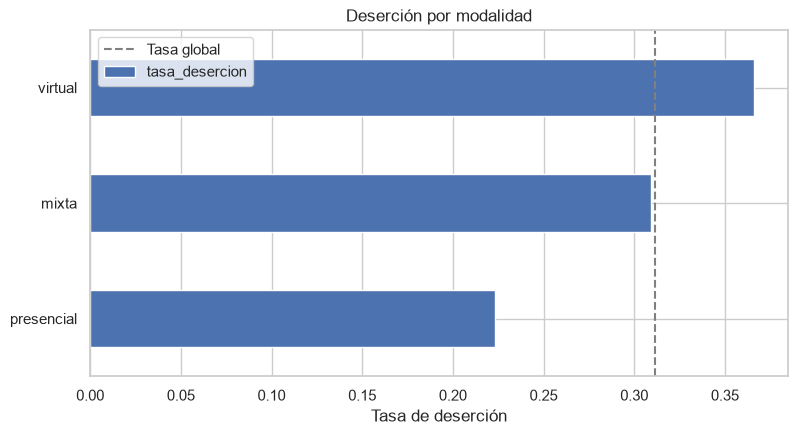

,tasa_desercion,aprendices
modalidad,,
virtual,0.366299,4712
mixta,0.309024,1906
presencial,0.223448,2900


In [6]:
graficar_tasa(df, "modalidad", "Deserción por modalidad")
tasa_por(df, "modalidad")

> **Observaciones:** _(completar después de ejecutar: qué se ve y qué implica para el modelo)._

## 4. Deserción en el tiempo (por cohorte)

La validación será temporal: entrenamos con cohortes antiguas y evaluamos con la más reciente. Si la tasa de deserción cambia mucho entre cohortes, el modelo podría comportarse distinto en la cohorte de prueba.

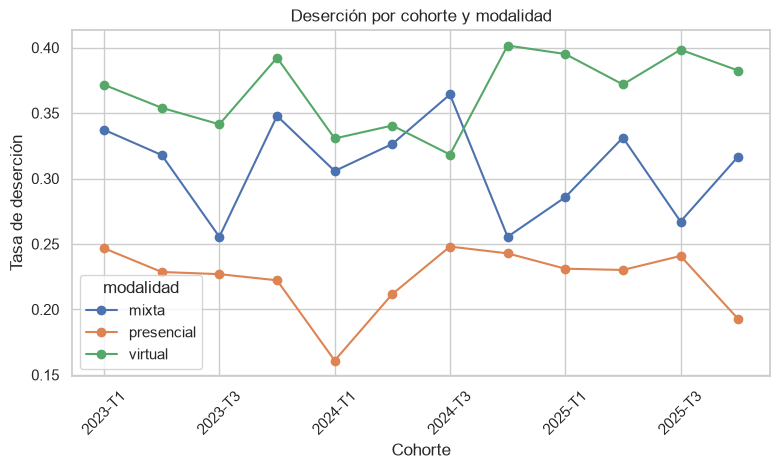

id_cohorte,2023-T1,2023-T2,2023-T3,2023-T4,2024-T1,2024-T2,2024-T3,2024-T4,2025-T1,2025-T2,2025-T3,2025-T4
aprendices,800,805,816,780,781,786,833,756,823,794,765,779


In [7]:
por_cohorte = (
    df.groupby(["id_cohorte", "modalidad"])[ETIQUETA].mean().unstack().sort_index()
)
ax = por_cohorte.plot(marker="o")
ax.set_ylabel("Tasa de deserción")
ax.set_xlabel("Cohorte")
ax.set_title("Deserción por cohorte y modalidad")
plt.xticks(rotation=45)
plt.show()
df["id_cohorte"].value_counts().sort_index().to_frame("aprendices").T

> **Observaciones:** _(completar después de ejecutar: qué se ve y qué implica para el modelo)._

## 5. Valores faltantes

En `docs/datos.md` documentamos que los nulos siguen reglas del negocio. Aquí lo comprobamos.

In [8]:
nulos = df.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
pd.DataFrame({"nulos": nulos, "porcentaje": (nulos / len(df)).round(3)})

,nulos,porcentaje
asistencia_porcentaje,4712,0.495
tasa_finalizacion_previa,3022,0.318
abandono_ultimo_curso,2647,0.278
meses_desde_ultimo_curso,2647,0.278
calidad_internet,679,0.071
horas_disponibles_estudio,679,0.071
dificultad_economica_reportada,679,0.071
promedio_calificaciones,1,0.000


In [9]:
reglas = {
    "asistencia nula ⇔ virtual": (df["asistencia_porcentaje"].isna() == (df["modalidad"] == "virtual")).all(),
    "historial nulo ⇔ primer curso": (df["meses_desde_ultimo_curso"].isna() == df["es_primer_curso"]).all(),
    "encuesta nula en las mismas filas": (
        df[["calidad_internet", "horas_disponibles_estudio", "dificultad_economica_reportada"]]
        .isna()
        .nunique(axis=1)
        .eq(1)
        .all()
    ),
}
pd.Series(reglas, name="se cumple")

asistencia nula ⇔ virtual            True
historial nulo ⇔ primer curso        True
encuesta nula en las mismas filas    True
Name: se cumple, dtype: bool

¿Los aprendices sin encuesta desertan más o menos? Si hay diferencia, el hecho de no responder es una señal útil para el modelo.

In [10]:
sin_encuesta = df["calidad_internet"].isna().map({True: "sin encuesta", False: "con encuesta"})
df.groupby(sin_encuesta)[ETIQUETA].agg(tasa_desercion="mean", aprendices="size")

,tasa_desercion,aprendices
calidad_internet,,
con encuesta,0.310782,8839
sin encuesta,0.318115,679


> **Observaciones:** _(completar después de ejecutar: qué se ve y qué implica para el modelo)._

## 6. Variables numéricas frente a la deserción

Comparamos la distribución de cada variable entre quienes desertaron y quienes no.

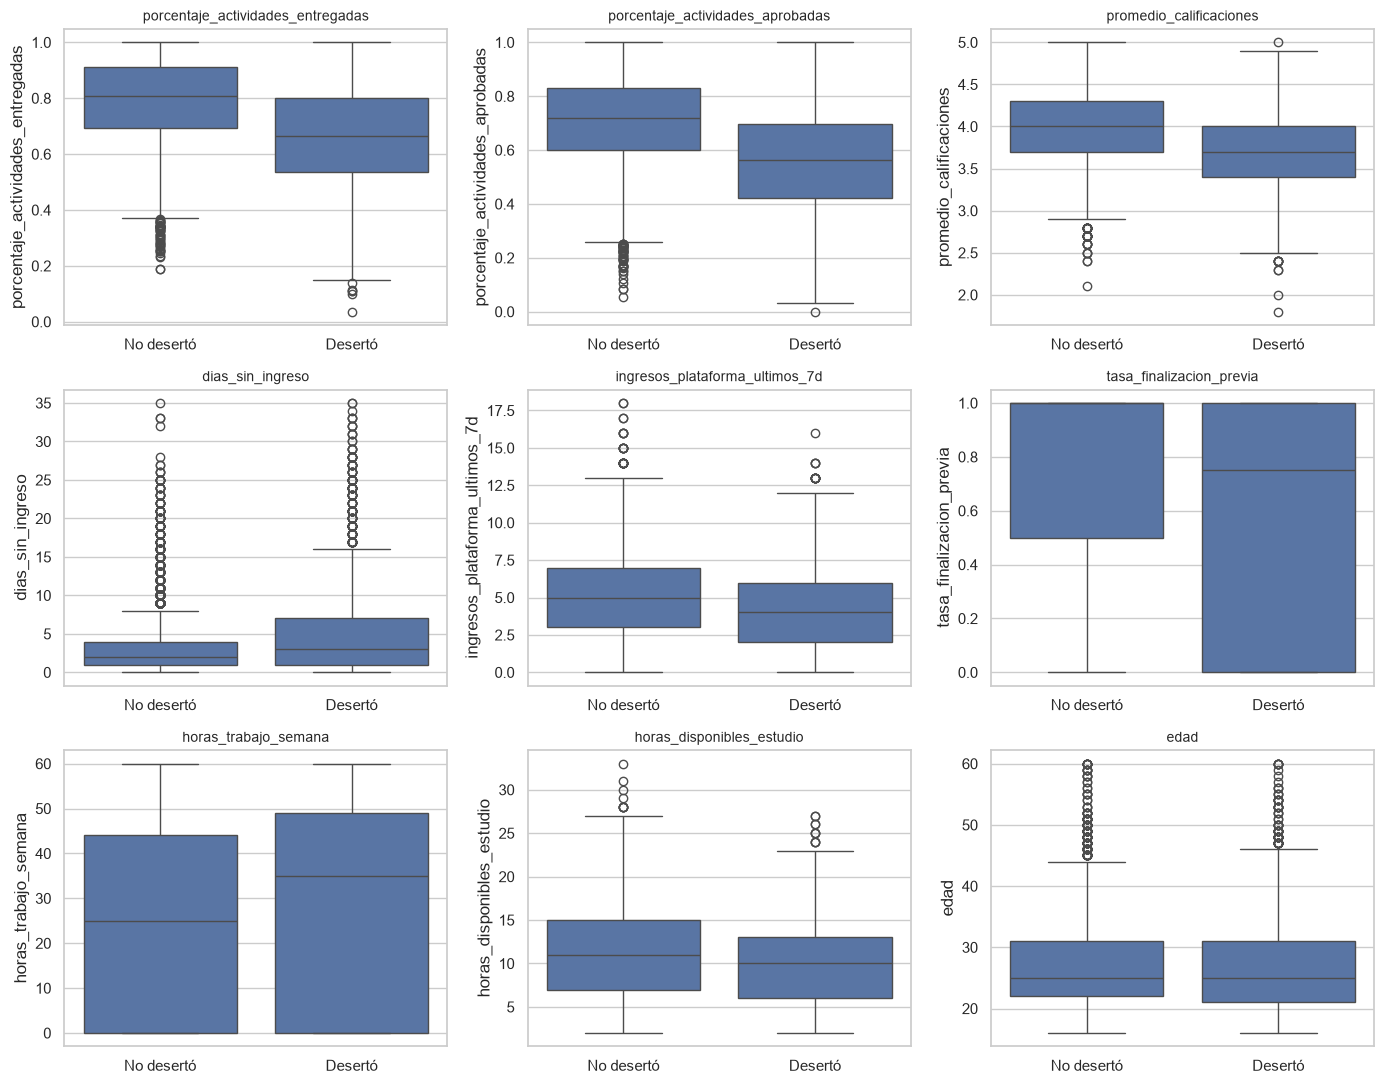

In [11]:
numericas = [
    "porcentaje_actividades_entregadas",
    "porcentaje_actividades_aprobadas",
    "promedio_calificaciones",
    "dias_sin_ingreso",
    "ingresos_plataforma_ultimos_7d",
    "tasa_finalizacion_previa",
    "horas_trabajo_semana",
    "horas_disponibles_estudio",
    "edad",
]
fig, ejes = plt.subplots(3, 3, figsize=(14, 11))
for ax, columna in zip(ejes.flat, numericas):
    sns.boxplot(data=df, x=ETIQUETA, y=columna, ax=ax)
    ax.set_xticks([0, 1], ["No desertó", "Desertó"])
    ax.set_xlabel("")
    ax.set_title(columna, fontsize=10)
fig.tight_layout()
plt.show()

In [12]:
df.groupby(ETIQUETA)[numericas].median().T.rename(columns={0: "mediana · no desertó", 1: "mediana · desertó"})

deserto,mediana · no desertó,mediana · desertó
porcentaje_actividades_entregadas,0.807,0.666
porcentaje_actividades_aprobadas,0.719,0.562
promedio_calificaciones,4.000,3.700
dias_sin_ingreso,2.000,3.000
ingresos_plataforma_ultimos_7d,5.000,4.000
tasa_finalizacion_previa,1.000,0.750
horas_trabajo_semana,25.000,35.000
horas_disponibles_estudio,11.000,10.000
edad,25.000,25.000


> **Observaciones:** _(completar después de ejecutar: qué se ve y qué implica para el modelo)._

## 7. Variables categóricas frente a la deserción

La línea punteada es la tasa global: las barras que se alejan de ella indican categorías con más o menos riesgo.

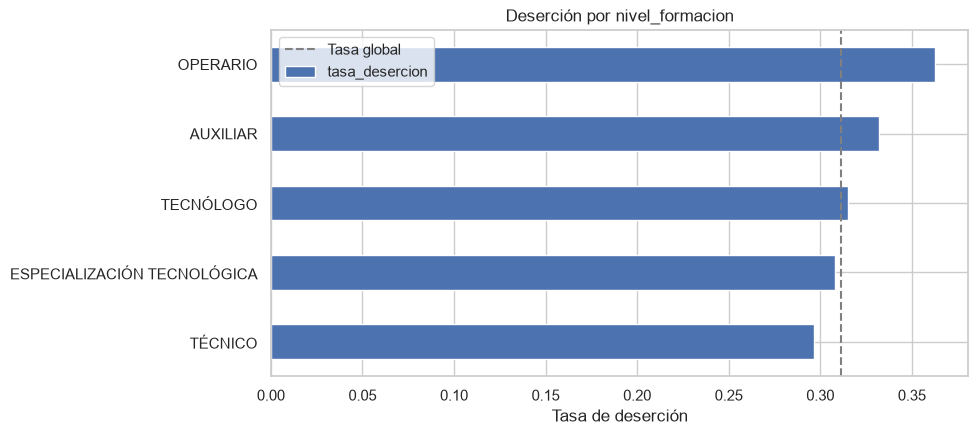

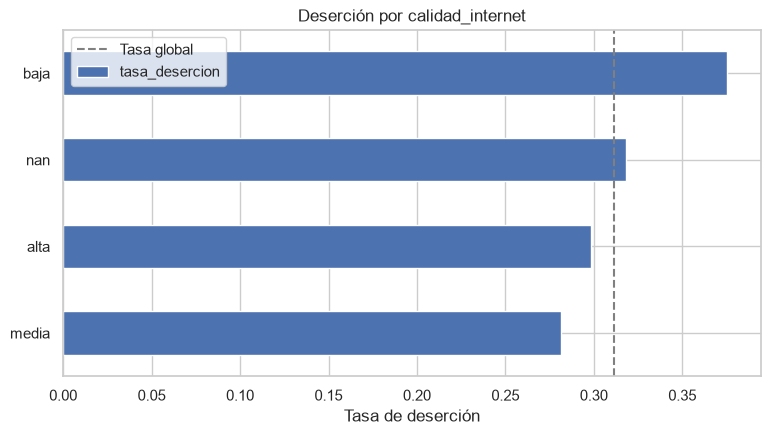

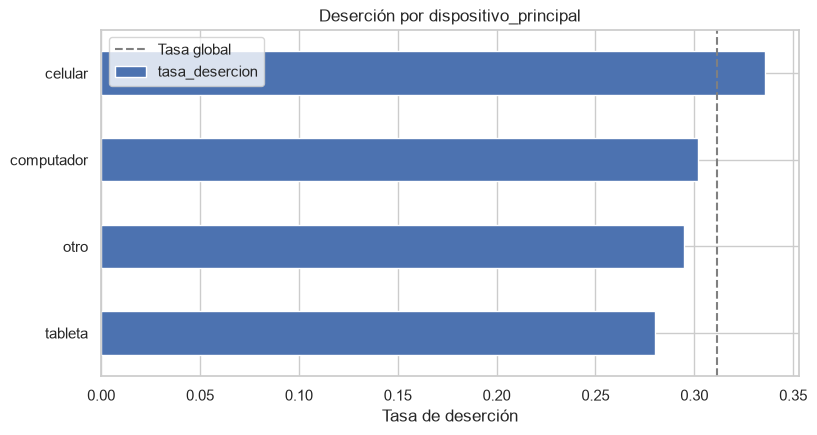

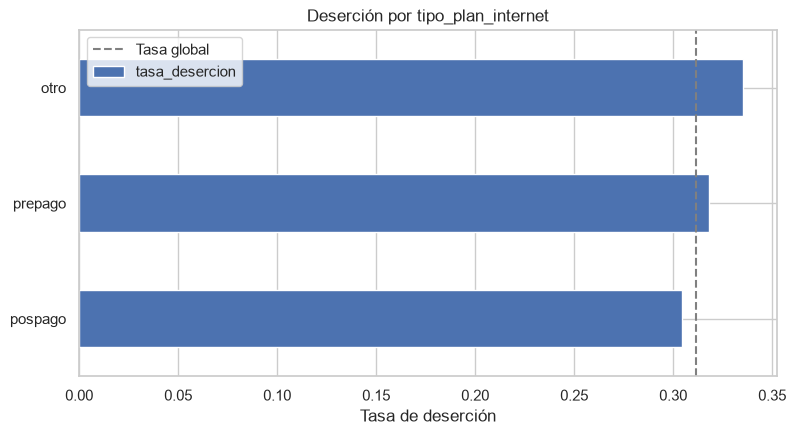

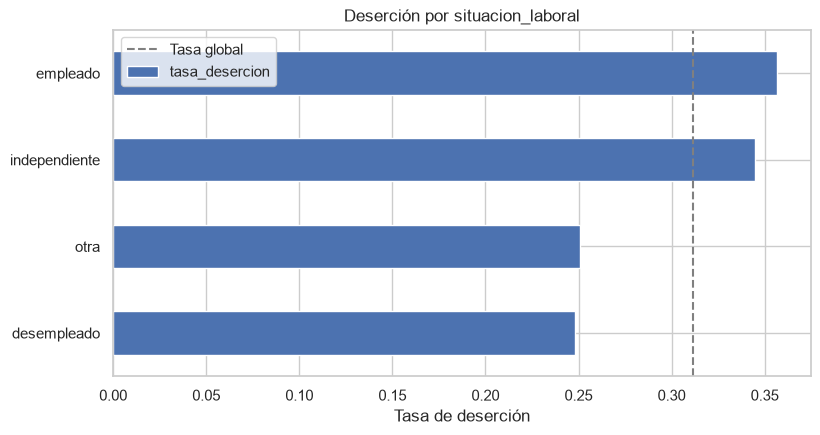

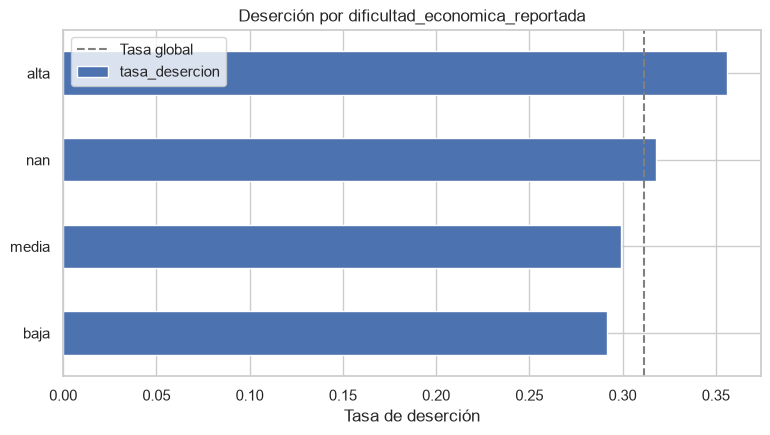

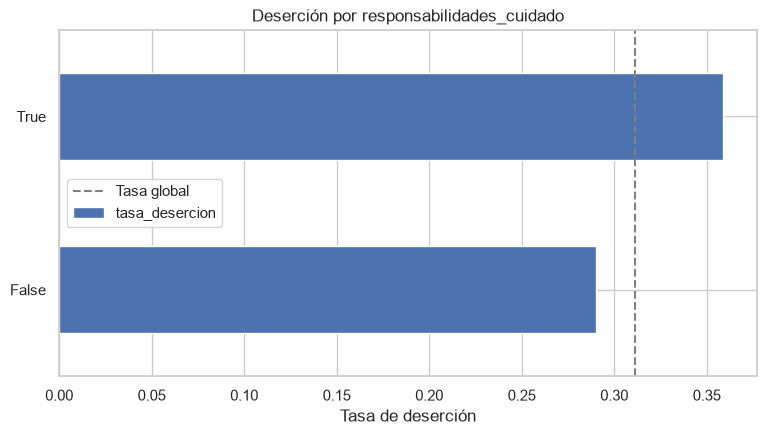

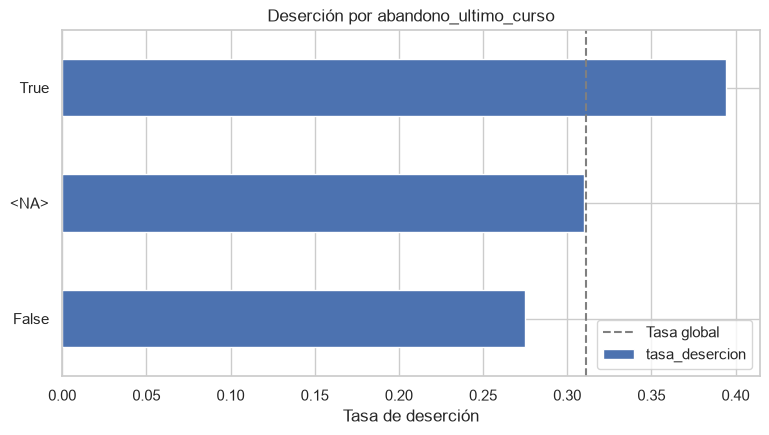

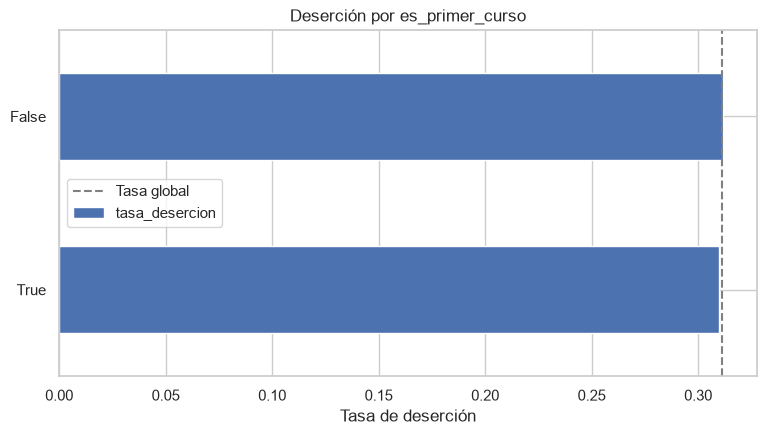

In [13]:
categoricas = [
    "nivel_formacion",
    "calidad_internet",
    "dispositivo_principal",
    "tipo_plan_internet",
    "situacion_laboral",
    "dificultad_economica_reportada",
    "responsabilidades_cuidado",
    "abandono_ultimo_curso",
    "es_primer_curso",
]
for columna in categoricas:
    graficar_tasa(df, columna)

> **Observaciones:** _(completar después de ejecutar: qué se ve y qué implica para el modelo)._

## 8. Relación entre variables numéricas

Correlaciones muy altas entre dos variables indican información repetida. No es un problema para LightGBM, pero sí para interpretar la regresión logística.

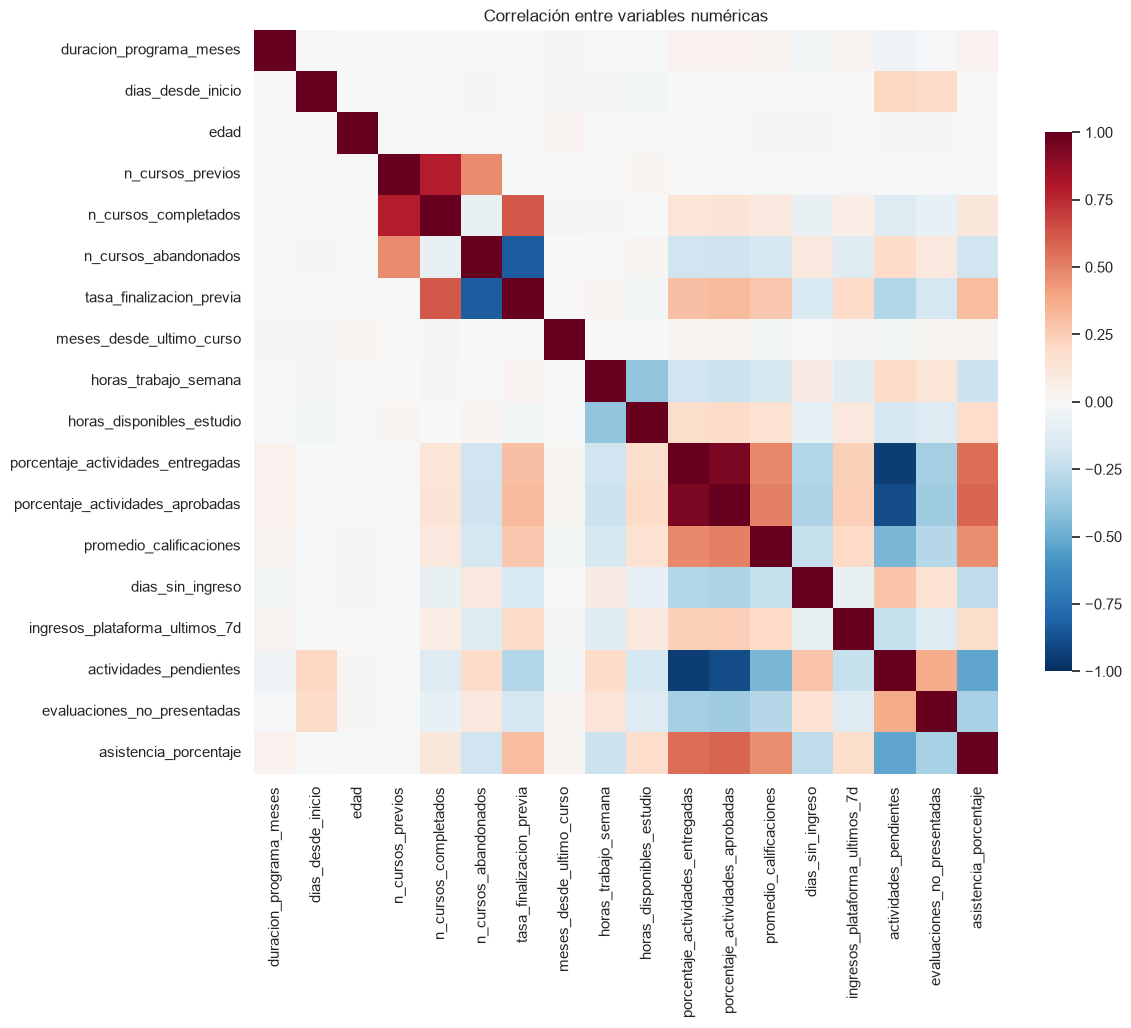

In [14]:
correlacion = df.select_dtypes("number").drop(columns=[ETIQUETA]).corr()
plt.figure(figsize=(12, 10))
sns.heatmap(correlacion, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7})
plt.title("Correlación entre variables numéricas")
plt.show()

In [15]:
pares = (
    correlacion.where(lambda m: ~m.isna())
    .stack()
    .rename("correlacion")
    .rename_axis(["variable_1", "variable_2"])
    .reset_index()
    .query("variable_1 < variable_2 and correlacion.abs() >= 0.6", engine="python")
    .sort_values("correlacion", key=abs, ascending=False)
)
pares

,variable_1,variable_2,correlacion
280,actividades_pendientes,porcentaje_actividades_entregadas,-0.946407
208,porcentaje_actividades_aprobadas,porcentaje_actividades_entregadas,0.944573
281,actividades_pendientes,porcentaje_actividades_aprobadas,-0.892679
96,n_cursos_abandonados,tasa_finalizacion_previa,-0.835036
75,n_cursos_completados,n_cursos_previos,0.782920
78,n_cursos_completados,tasa_finalizacion_previa,0.624083


> **Observaciones:** _(completar después de ejecutar: qué se ve y qué implica para el modelo)._

## 9. Punto de partida para la equidad

La tabla de auditoría (`sexo`) **no entra al modelo**. Aquí solo miramos las tasas de deserción de partida por grupo: si ya son distintas en los datos, hay que tenerlo en cuenta al interpretar las métricas por subgrupo en el cuaderno 04.

In [16]:
auditoria = pd.read_parquet(RUTA_AUDITORIA)
con_auditoria = df[["id_aprendiz", ETIQUETA]].merge(auditoria[["id_aprendiz", "sexo"]], on="id_aprendiz")
assert len(con_auditoria) == len(df), "La tabla de auditoría no coincide con los datos procesados"
tasa_por(con_auditoria, "sexo")

,tasa_desercion,aprendices
sexo,,
M,0.324274,4305
F,0.300595,5213


> **Observaciones:** _(completar después de ejecutar: qué se ve y qué implica para el modelo)._

## 10. Conclusiones

_(Completar con los hallazgos de cada sección.)_

**Sobre la variable objetivo y la validación:**
-

**Variables más relacionadas con la deserción:**
-

**Decisiones para `features.py`:**
- Valores faltantes:
- Variables redundantes:
- Variables nuevas a construir:

**A tener en cuenta en la evaluación (cuaderno 04):**
-